# Experiment 2: The Eight Queens Problem
**CSAI4014 AISR Laboratory** | Name: `<Suhani Baderia>` | SAP ID: `<500119327>` | Batch: `<4>`

Place n queens on an n × n board so that no two share a row, column or diagonal.
Two methods are compared:

* **Method A – brute force over permutations.** One queen per column, rows form a permutation,
  so only diagonals need checking. Visits all n! complete placements.
* **Method B – backtracking (depth-first search with pruning).** Place queens column by column and
  abandon a partial placement as soon as it has a conflict. Uses sets for O(1) conflict checks.

"Nodes visited" = complete placements tested (A) or partial placements expanded (B).

In [1]:
import os
import platform
import time
from itertools import permutations
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3})


def cpu_name():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if "model name" in line:
                    return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)
print("OS    :", platform.platform())
print("CPU   :", cpu_name(), "| logical cores:", os.cpu_count())

Python: 3.10.0 | NumPy: 2.2.6 | Matplotlib: 3.10.9
OS    : Windows-10-10.0.26300-SP0
CPU   : Intel64 Family 6 Model 154 Stepping 3, GenuineIntel | logical cores: 16


## Method A – brute force over permutations

In [2]:
def solve_bruteforce(n):
    """Return (solutions, nodes_visited). solution[c] = row of the queen in column c."""
    solutions, nodes = [], 0
    for perm in permutations(range(n)):
        nodes += 1
        if len({r + c for c, r in enumerate(perm)}) == n and len({r - c for c, r in enumerate(perm)}) == n:
            solutions.append(perm)
    return solutions, nodes

## Method B – backtracking

In [3]:
def solve_backtracking(n):
    """Depth-first placement column by column with pruning."""
    solutions, rows, diag1, diag2, placement = [], set(), set(), set(), []
    nodes = 0

    def place(col):
        nonlocal nodes
        if col == n:
            solutions.append(tuple(placement))
            return
        for r in range(n):
            if r in rows or (r + col) in diag1 or (r - col) in diag2:
                continue                      # prune: conflict with an earlier queen
            nodes += 1                        # a new, conflict-free partial placement
            rows.add(r); diag1.add(r + col); diag2.add(r - col); placement.append(r)
            place(col + 1)
            rows.remove(r); diag1.remove(r + col); diag2.remove(r - col); placement.pop()

    place(0)
    return solutions, nodes


def is_valid(sol):
    n = len(sol)
    return all(sol[i] != sol[j] and abs(sol[i] - sol[j]) != j - i
               for i in range(n) for j in range(i + 1, n))

## Run both methods for n = 4 … 10
Each timing is the best of `REPEATS` runs (reduces noise from other programs). Brute force at
n = 10 checks 3 628 800 permutations and takes several seconds.

In [4]:
REPEATS = 3
known = {4: 2, 5: 10, 6: 4, 7: 40, 8: 92, 9: 352, 10: 724}
results = []
for n in range(4, 11):
    row = [n]
    for solver in (solve_bruteforce, solve_backtracking):
        reps = 1 if (solver is solve_bruteforce and n >= 10) else REPEATS
        best = float("inf")
        for _ in range(reps):
            t0 = time.perf_counter()
            sols, nodes = solver(n)
            best = min(best, time.perf_counter() - t0)
        assert all(is_valid(s) for s in sols)
        row += [len(sols), nodes, best]
    assert row[1] == row[4] == known[n], f"count mismatch at n={n}"
    results.append(row)
    print(f"n={n:2d} | brute: {row[1]:4d} sols {row[2]:>9,d} nodes {row[3]*1e3:9.2f} ms"
          f" | backtrack: {row[4]:4d} sols {row[5]:>7,d} nodes {row[6]*1e3:8.2f} ms")

res = np.array(results, dtype=float)
np.savetxt("tables/T2_1_solutions_nodes_time.csv", res, delimiter=",",
           fmt=["%d", "%d", "%d", "%.6f", "%d", "%d", "%.6f"],
           header="n,BF solutions,BF nodes,BF time (s),BT solutions,BT nodes,BT time (s)", comments="")
print("\nBoth methods give the same solution count for every n:", bool(np.all(res[:, 1] == res[:, 4])))

n= 4 | brute:    2 sols        24 nodes      0.02 ms | backtrack:    2 sols      16 nodes     0.02 ms
n= 5 | brute:   10 sols       120 nodes      0.12 ms | backtrack:   10 sols      53 nodes     0.08 ms
n= 6 | brute:    4 sols       720 nodes      0.73 ms | backtrack:    4 sols     152 nodes     0.24 ms
n= 7 | brute:   40 sols     5,040 nodes      5.66 ms | backtrack:   40 sols     551 nodes     0.88 ms
n= 8 | brute:   92 sols    40,320 nodes     47.73 ms | backtrack:   92 sols   2,056 nodes     3.27 ms
n= 9 | brute:  352 sols   362,880 nodes    449.21 ms | backtrack:  352 sols   8,393 nodes    15.38 ms
n=10 | brute:  724 sols 3,628,800 nodes   4725.65 ms | backtrack:  724 sols  35,538 nodes    67.25 ms

Both methods give the same solution count for every n: True


## Figure 2.1 – first solution found for n = 8

First solution (row of queen in columns 0..7): (0, 4, 7, 5, 2, 6, 1, 3)


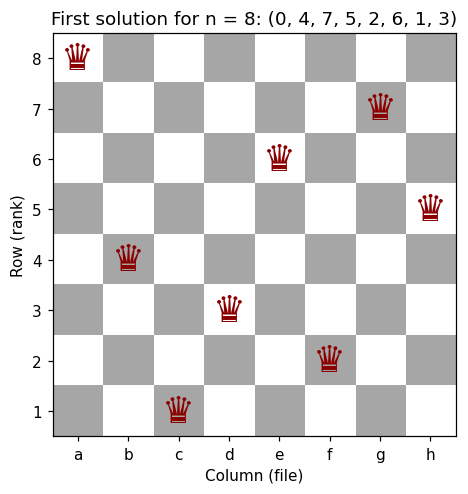

In [5]:
sols8, _ = solve_backtracking(8)
first = sols8[0]
print("First solution (row of queen in columns 0..7):", first)

fig, ax = plt.subplots(figsize=(4.6, 4.6))
board = np.add.outer(np.arange(8), np.arange(8)) % 2
ax.imshow(board, cmap="Greys", alpha=0.35, extent=(-0.5, 7.5, 7.5, -0.5))
for c, r in enumerate(first):
    ax.text(c, r, "♛", ha="center", va="center", fontsize=24, color="darkred")
ax.set_xticks(range(8)); ax.set_yticks(range(8))
ax.set_xticklabels("abcdefgh"); ax.set_yticklabels(range(8, 0, -1))
ax.set_xlabel("Column (file)"); ax.set_ylabel("Row (rank)")
ax.grid(False)
ax.set_title(f"First solution for n = 8: {first}")
fig.tight_layout()
fig.savefig("figs/fig2_1_first_solution_n8.png")
plt.show()

## Figure 2.2 – run time against board size (log scale)

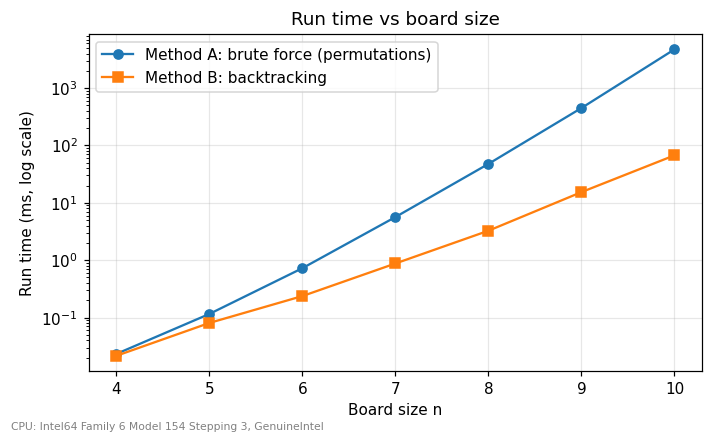

Time ratio t(n)/t(n-1), brute force : [ 5.   6.3  7.8  8.4  9.4 10.5]
Time ratio t(n)/t(n-1), backtracking: [3.7 2.9 3.7 3.7 4.7 4.4]
Speed-up of backtracking at n = 10  : 70 x


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(res[:, 0], res[:, 3] * 1e3, "o-", label="Method A: brute force (permutations)")
ax.semilogy(res[:, 0], res[:, 6] * 1e3, "s-", label="Method B: backtracking")
ax.set_xlabel("Board size n")
ax.set_ylabel("Run time (ms, log scale)")
ax.set_title("Run time vs board size")
ax.legend()
fig.text(0.01, 0.01, f"CPU: {cpu_name()}", fontsize=7, color="gray")
fig.tight_layout()
fig.savefig("figs/fig2_2_runtime_vs_n.png")
plt.show()

growth_bf = res[1:, 3] / res[:-1, 3]
growth_bt = res[1:, 6] / res[:-1, 6]
print("Time ratio t(n)/t(n-1), brute force :", np.round(growth_bf, 1))
print("Time ratio t(n)/t(n-1), backtracking:", np.round(growth_bt, 1))
print("Speed-up of backtracking at n = 10  :", round(res[-1, 3] / res[-1, 6]), "x")